In [1]:
pip install yfinance

Defaulting to user installation because normal site-packages is not writeable
INFO: pip is looking at multiple versions of yfinance to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of yfinance to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 19.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [yfinance]3/7 [peewee]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt # ดาวน์โหลดข้อมูล Apple Stock
df = yf.download('AAPL',start='2023-06-30', end='2024-06-30')

/Users/napat/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
[*********************100%***********************]  1 of 1 completed


Price            Close        High         Low        Open    Volume  \
Date                                                                   
2023-06-30  191.123474  191.625984  188.453237  188.817817  85213200   
2023-07-03  189.635635  191.034795  188.945896  190.936256  31458200   
2023-07-05  188.522171  190.147951  187.822584  188.758654  46920300   
2023-07-06  188.995132  189.202057  186.423434  187.054042  45094300   
2023-07-07  187.881744  189.842546  187.448214  188.601042  46815000   

Price       Daily_Return  
Date                      
2023-06-30           NaN  
2023-07-03     -0.007785  
2023-07-05     -0.005872  
2023-07-06      0.002509  
2023-07-07     -0.005891  

จานวนวันซื้อขาย: 251

ราคาเปิดเฉลี่ย: $181.88
ราคาปิด เฉลี่ย: $181.93
ราคาสูงสุด:$218.12
ราคาต ่าสุด: $162.31

ผลตอบแทนเฉลี่ย:0.044%
ความเบี่ยงเบนมาตรฐาน:1.379%

ปริมาณการซื้อขาย เฉลี่ย:60,399,447


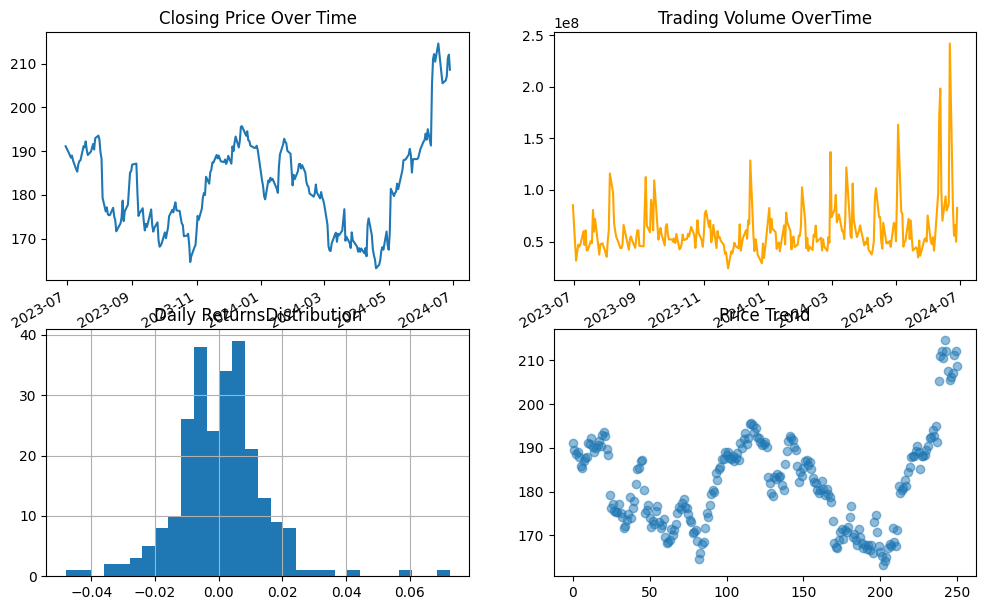

In [4]:
# 1. ตรวจสอบข้อมูล
print(df.head())
print(f'\nจานวนวันซื้อขาย: {len(df)}')
# 2. สถิติราคา
print(f'\nราคาเปิดเฉลี่ย: ${df["Open"].mean().mean():.2f}')
print(f'ราคาปิด เฉลี่ย: ${df["Close"].mean().mean():.2f}')
df.columns = df.columns.get_level_values(0)
print(f'ราคาสูงสุด:${df["High"].max():.2f}')
print(f'ราคาต ่าสุด: ${df["Low"].min():.2f}')
# 3. ความผันผวน
df['Daily_Return'] = df['Close'].pct_change()
print(f'\nผลตอบแทนเฉลี่ย:{df["Daily_Return"].mean()*100:.3f}%')
print(f'ความเบี่ยงเบนมาตรฐาน:{df["Daily_Return"].std()*100:.3f}%')
# 4. ปริมาณการซื้อขาย
print(f'\nปริมาณการซื้อขาย เฉลี่ย:{df["Volume"].mean():,.0f}')
# 5. กราฟแสดง
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
df['Close'].plot(ax=axes[0, 0])
axes[0, 0].set_title('Closing Price Over Time')
df['Volume'].plot(ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Trading Volume OverTime')
df['Daily_Return'].hist(bins=30, ax=axes[1, 0])
axes[1, 0].set_title('Daily ReturnsDistribution')
axes[1, 1].scatter(range(len(df)), df['Close'], alpha=0.5)
axes[1,1].set_title('Price Trend')
plt.show()

In [5]:
import yfinance as yf
import pandas as pd
import numpy as np

In [6]:
df = yf.download('AAPL', start='2023-07-01', end=None)
df.columns = df.columns.get_level_values(0)
df['Daily_Return'] = df['Close'].pct_change()
df = df.dropna() # ลบแถวแรกที่มีค่า NaN จากการคำนวณ Daily Return

[*********************100%***********************]  1 of 1 completed


In [7]:
df_2023_h2 = df.loc['2023-07-01':'2023-12-31']

In [8]:
df_2024 = df.loc['2024-01-01':]

In [9]:
def calculate_stats(data, name):
    mean_return = data['Daily_Return'].mean() * 100
    std_dev = data['Daily_Return'].std() * 100
    total_return = (data['Close'].iloc[-1] / data['Close'].iloc[0] - 1) * 100
    return pd.Series({
        'ช่วงเวลา': name,
        'ผลตอบแทนเฉลี่ย/วัน (%)': f'{mean_return:.3f}',
        'ความผันผวน/วัน (Std Dev %)': f'{std_dev:.3f}',
        'ผลตอบแทนรวม (%)': f'{total_return:.2f}'
    })

In [10]:
stats_2023_h2 = calculate_stats(df_2023_h2, '2023 H2 (แกว่งตัว)')
stats_2024 = calculate_stats(df_2024, '2024 (พุ่งขึ้น)')

results = pd.DataFrame([stats_2023_h2, stats_2024]).set_index('ช่วงเวลา')
print("\n--- ผลการเปรียบเทียบสถิติ AAPL ---")
print(results)


--- ผลการเปรียบเทียบสถิติ AAPL ---
                   ผลตอบแทนเฉลี่ย/วัน (%) ความผันผวน/วัน (Std Dev %)  \
ช่วงเวลา                                                               
2023 H2 (แกว่งตัว)                  0.009                      1.187   
2024 (พุ่งขึ้น)                     0.100                      1.724   

                   ผลตอบแทนรวม (%)  
ช่วงเวลา                            
2023 H2 (แกว่งตัว)            0.90  
2024 (พุ่งขึ้น)              89.60  


In [11]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
tickers = ['AAPL', '^GSPC', '^IXIC'] # AAPL, S&P 500, NASDAQ Composite
df = yf.download (tickers, start='2024-01-01', end=None) ['Close']

[*********************100%***********************]  3 of 3 completed


In [13]:
cumulative_returns = (df / df.iloc[0]) - 1

<Figure size 1200x600 with 0 Axes>

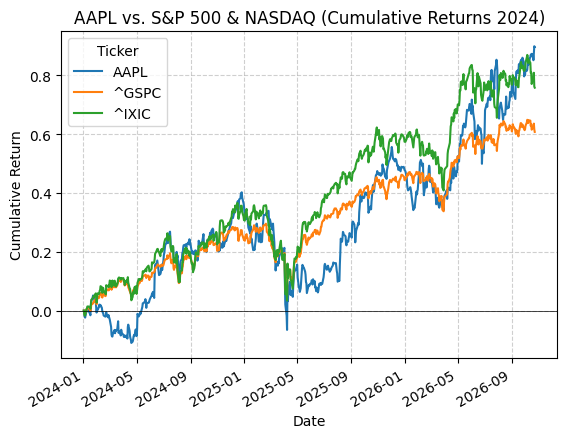


--- ผลตอบแทนรวม ณ วันล่าสุด (%) ---
Ticker
AAPL     89.60
^IXIC    75.78
^GSPC    60.74
Name: 2026-10-23 00:00:00, dtype: float64


In [14]:
plt.figure(figsize=(12, 6))
cumulative_returns.plot()

plt.title('AAPL vs. S&P 500 & NASDAQ (Cumulative Returns 2024)')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.legend(title='Ticker')
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(0, color='black', linestyle='-', linewidth=0.5) # เส้นศูนย์
plt.show()

latest_returns = cumulative_returns.iloc[-1] * 100
print("\n--- ผลตอบแทนรวม ณ วันล่าสุด (%) ---")
print(latest_returns.sort_values(ascending=False).round(2))